# 06 传感器 / 海流图等级敏感性：误差界 → 最长可认证桥长

统一参数、主实验世界（8 m 宽）。每次只改一个声明误差界，真实世界的对应误差同步缩放，使假设 A1–A2 仍成立；
其余参数不变。对每个设置在桥长 9–51 m（步长 2 m）上做入口认证，取最长放行桥长；
再在该桥长上跑一次闭环，检查误差界仍覆盖真实误差、没有撞墙。

| 扫描项 | 统一参数值 | 扫描值 | 真实世界同步 |
|---|---|---|---|
| 陀螺零偏界 `gyro_bound` (rad/s) | 0.0008 | 0.0003, 0.0005, 0.0008, 0.0012, 0.002, 0.003 | 真实零偏 = 界 − 0.00025（噪声 ±0.00025 不变） |
| 速度误差界倍数（`speed_error_floor/ratio/lateral` 同乘） | ×1 | ×0.5, ×1, ×1.5, ×2, ×3 | 真实速度误差来自船模失配，不变（×0.5 时由覆盖率检查验证是否仍成立） |
| 射流幅值误差界 `jet_amplitude_error_bound` (m/s) | 0.22 | 0.05, 0.10, 0.15, 0.22, 0.30 | 真实射流误差 = 0.9 × 界 |
| 背景流误差界倍数（北 0.010 / 东 0.015 同乘） | ×1 | ×0.5, ×1, ×2, ×3 | 真实偏置 = 0.5 × 界，潮汐幅值 = 0.2 × 东向界 |

In [1]:
import sys, time
from pathlib import Path
from dataclasses import replace
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from bridge_sim.core import cfg as CFG
from bridge_sim.ext import pmap, gate_and_check, closed_loop_check, DEFAULT_SCENARIO

RES = ROOT/'results'; RES.mkdir(exist_ok=True)
FIG = ROOT/'figures'; FIG.mkdir(exist_ok=True)
WORKERS = 4
LENGTHS = list(range(9, 52, 2))
pd.set_option('display.width', 200)

def setting(kind, value):
    s = DEFAULT_SCENARIO
    if kind == 'gyro':
        return replace(s, gyro_bias=max(value - 0.00025, 0.), cfg_overrides=(('gyro_bound', value),))
    if kind == 'speed':
        return replace(s, cfg_overrides=(('speed_error_floor', CFG.speed_error_floor*value),
                                         ('speed_error_ratio', CFG.speed_error_ratio*value),
                                         ('speed_error_lateral', CFG.speed_error_lateral*value)))
    if kind == 'jet':
        return replace(s, jet_amplitude_error=0.9*value, cfg_overrides=(('jet_amplitude_error_bound', value),))
    if kind == 'current':
        bn, be = CFG.current_north_error_bound*value, CFG.current_east_error_bound*value
        return replace(s, current_north_bias=0.5*bn, current_east_bias=0.5*be, tide_amplitude=0.2*be,
                       cfg_overrides=(('current_north_error_bound', bn), ('current_east_error_bound', be)))
    raise ValueError(kind)

SWEEPS = {
    'gyro':    ([0.0003, 0.0005, 0.0008, 0.0012, 0.002, 0.003], 0.0008, 'Gyro bias bound (rad/s)'),
    'speed':   ([0.5, 1.0, 1.5, 2.0, 3.0], 1.0, 'Speed-error bound (x nominal)'),
    'jet':     ([0.05, 0.10, 0.15, 0.22, 0.30], 0.22, 'Jet amplitude error bound (m/s)'),
    'current': ([0.5, 1.0, 2.0, 3.0], 1.0, 'Background-current error bound (x nominal)'),
}

In [2]:
path = RES/'sensitivity_gate.csv'
if path.exists():
    gate = pd.read_csv(path); print('loading', path.name)
else:
    t0 = time.time()
    keys = [(k, v, L) for k, (vals, _, _) in SWEEPS.items() for v in vals for L in LENGTHS]
    rows = pmap(gate_and_check, [dict(s=replace(setting(k, v), length=float(L))) for k, v, L in keys], workers=WORKERS)
    gate = pd.DataFrame(rows); gate['kind'] = [k for k, _, _ in keys]; gate['value'] = [v for _, v, _ in keys]
    gate.to_csv(path, index=False); print(f'{len(gate)} gate checks in {time.time()-t0:.0f} s')
assert 'error' not in gate or gate['error'].isna().all()
lim = (gate[gate.admitted.astype(bool)].groupby(['kind', 'value'])['length'].max()
       .reindex(pd.MultiIndex.from_tuples([(k, v) for k, (vals, _, _) in SWEEPS.items() for v in vals], names=['kind', 'value'])))
lim = lim.rename('longest certified (m)').to_frame()
lim.set_axis(pd.MultiIndex.from_tuples([(k, f'{v:g}') for k, v in lim.index], names=['kind', 'value']))

loading sensitivity_gate.csv


longest certified (m)
kind    value                        
gyro    0.0003                   21.0
        0.0005                   21.0
        0.0008                   19.0
        0.0012                   19.0
        0.002                    17.0
        0.003                    15.0
speed   0.5                      23.0
        1                        19.0
        1.5                      17.0
        2                        15.0
        3                        13.0
jet     0.05                     39.0
        0.1                      31.0
        0.15                     25.0
        0.22                     19.0
        0.3                      15.0
current 0.5                      21.0
        1                        19.0
        2                        17.0
        3                        15.0

In [3]:
path = RES/'sensitivity_check.csv'
if path.exists():
    chk = pd.read_csv(path); print('loading', path.name)
else:
    jobs = [(k, v, L) for (k, v), L in lim['longest certified (m)'].dropna().items()]
    rows = pmap(closed_loop_check, [dict(s=replace(setting(k, v), length=float(L))) for k, v, L in jobs], workers=WORKERS)
    chk = pd.DataFrame(rows); chk['kind'] = [k for k, _, _ in jobs]; chk['value'] = [v for _, v, _ in jobs]
    chk.to_csv(path, index=False)
assert 'error' not in chk or chk['error'].isna().all()
from bridge_sim.ext import make_case, run_case_ext
chk['entry_margin'] = [gate.loc[(gate.kind == k) & (gate.value == v) & (gate.length == L), 'entry_margin'].iloc[0]
                       for k, v, L in zip(chk.kind, chk.value, chk.length)]
show = chk[['kind', 'value', 'length', 'entry_margin', 'admitted', 'completed', 'collided', 'min_clearance', 'cov_N', 'cov_E', 'cov_heading', 'cov_E_blind']].copy()
show['value'] = show['value'].map('{:g}'.format)
show.round(4)

loading sensitivity_check.csv


,kind,value,length,entry_margin,admitted,completed,collided,min_clearance,cov_N,cov_E,cov_heading,cov_E_blind
0,gyro,0.0003,21.0,0.0948,True,True,False,1.1879,0.8575,0.8178,0.9277,0.7128
1,gyro,0.0005,21.0,0.0269,True,True,False,1.2199,0.8575,0.8177,0.9281,0.6953
2,gyro,0.0008,19.0,0.2458,True,True,False,1.4419,0.8575,0.8174,0.9287,0.6513
3,gyro,0.0012,19.0,0.1354,True,True,False,1.3982,0.8575,0.8172,0.9295,0.6216
4,gyro,0.002,17.0,0.2080,True,True,False,1.5598,0.8575,0.8166,0.9310,0.5725
5,gyro,0.003,15.0,0.2456,True,True,False,1.7649,0.8575,0.8159,0.9334,0.5640
6,speed,0.5,23.0,0.0400,True,True,False,1.2490,0.8575,0.8525,0.9287,0.6947
7,speed,1,19.0,0.2458,True,True,False,1.4419,0.8575,0.8174,0.9287,0.6513
8,speed,1.5,17.0,0.2266,True,True,False,1.4923,0.8575,0.7852,0.9287,0.6124
9,speed,2,15.0,0.2199,True,True,False,1.5053,0.8575,0.7553,0.9287,0.5997


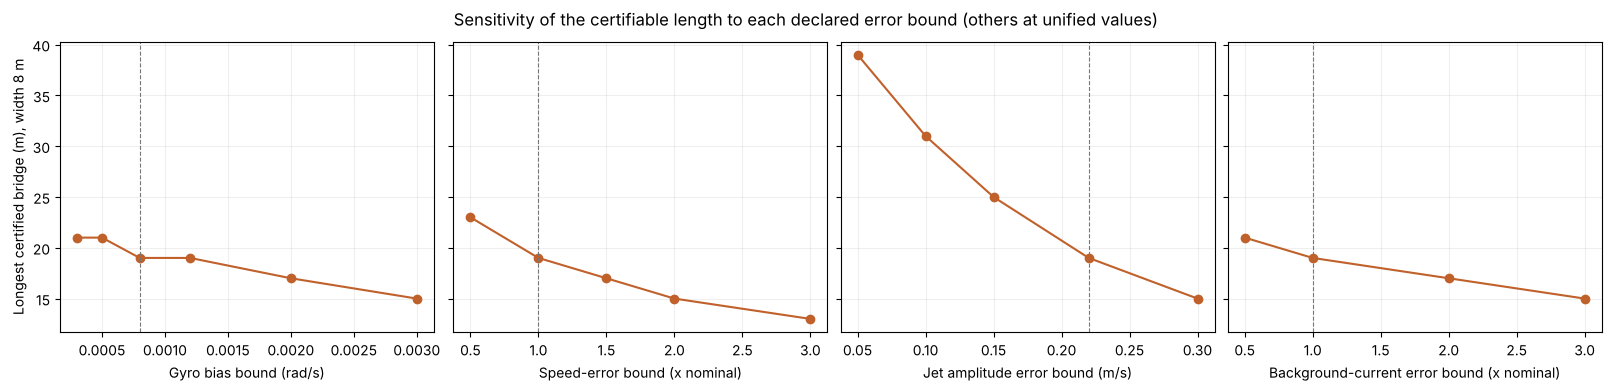

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), layout='constrained', sharey=True)
for ax, (k, (vals, nominal, label)) in zip(axes, SWEEPS.items()):
    y = lim.loc[k, 'longest certified (m)']
    ax.plot(vals, y.values, 'o-', color='#c0612b')
    ax.axvline(nominal, color='#777', ls='--', lw=.8)
    ax.set(xlabel=label); ax.grid(alpha=.2)
axes[0].set_ylabel('Longest certified bridge (m), width 8 m')
fig.suptitle('Sensitivity of the certifiable length to each declared error bound (others at unified values)')
fig.savefig(FIG/'sensitivity.png', dpi=200); fig.savefig(FIG/'sensitivity.pdf')
plt.show()

In [5]:
# Requirement table: the loosest bound on each item (others nominal) that still certifies a target length
targets = [15, 19, 25, 31]
req = {}
for k, (vals, nominal, label) in SWEEPS.items():
    y = lim.loc[k, 'longest certified (m)']
    req[label] = {f'{T} m': (max([v for v, L in zip(vals, y.values) if np.isfinite(L) and L >= T], default=np.nan)) for T in targets}
req = pd.DataFrame(req).T
req.to_csv(RES/'sensitivity_requirements.csv')
req

,15 m,19 m,25 m,31 m
Gyro bias bound (rad/s),0.003,0.0012,NaN,NaN
Speed-error bound (x nominal),2.000,1.0000,NaN,NaN
Jet amplitude error bound (m/s),0.300,0.2200,0.15,0.1
Background-current error bound (x nominal),3.000,1.0000,NaN,NaN


## 结论

数字取自上面的实际运行（统一参数，横荡速度误差界 0.015 m/s，主实验世界，8 m 宽，2 m 步长；统一参数下最长可认证 19 m）。

| 扫描项 | 更好 → 更差 | 最长可认证桥长 (m) |
|---|---|---|
| 射流幅值误差界 (m/s) | 0.05 / 0.10 / 0.15 / **0.22** / 0.30 | 39 / 31 / 25 / **19** / 15 |
| 陀螺零偏界 (rad/s) | 0.0003 / 0.0005 / **0.0008** / 0.0012 / 0.002 / 0.003 | 21 / 21 / **19** / 19 / 17 / 15 |
| 速度误差界倍数 | ×0.5 / **×1** / ×1.5 / ×2 / ×3 | 23 / **19** / 17 / 15 / 13 |
| 背景流误差界倍数 | ×0.5 / **×1** / ×2 / ×3 | 21 / **19** / 17 / 15 |

- **射流误差界是最大的杠杆**：从 0.22 降到 0.10 m/s，可认证桥长从 19 m 增加到 31 m；降到 0.05 m/s，增加到 39 m。
  陀螺、背景流精度提高一倍只多 2 m；速度误差界减半多 4 m（横荡误差界放宽到 0.015 后，速度项的份量比以前大）。
- **工程含义**：想过更长的桥，应该优先花在海流知识上（更好的海流图，或进桥前实测射流），其次是航速/横漂估计，而不是更贵的陀螺。
  要认证 25 m 的桥，射流误差界需 ≤ 0.15 m/s；31 m 需 ≤ 0.10 m/s；其余三项在扫描范围内单独改进都达不到 25 m。
- **闭环检查**：20 个最长认证点全部通过，撞墙 0，认证丢失 0，误差界全程覆盖（最大 0.93 倍）。速度误差界缩到 ×0.5 时仍然覆盖（东向 0.85 倍）。

**入口裕度阈值（2026-11-08 加入方法）。** 早一轮运行中，射流误差界 0.15、桥长 29 m 的入口裕度只有 +0.00006 m，放行后下一个控制步即认证丢失（船仍在桥口前 8.5 m）。
裕度贴近 0 时，数值预测与实际推力限幅、平滑候选之间的微小差别就足以让下一步失败，A3 的递归可行性在边界上不成立。
因此方法加入 `admission_margin = 0.02 m`：最佳航速的预测裕度至少 0.02 m 才放行（所有方法、所有实验同一阈值）。本轮全部结果都是带这一阈值重新仿真的，所有放行运行均未出现认证丢失。